# CGCNN

A Crystal Graph Convolutional Neural Network in PyTorch, implemented following the CaMML workshop notebook. Run `scripts/download_reference.py` first; it places the workshop's helper file and dataset in `../reference/camml/`.


## 0. Environment

Run this cell first. Use CPU for the first small experiment.


In [5]:
from pathlib import Path
import sys
import random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
REFERENCE = ROOT / "reference" / "camml"
if not (REFERENCE / "utils.py").exists():
    raise FileNotFoundError("Run uv run python scripts/download_reference.py from the repository folder.")
sys.path.insert(0, str(REFERENCE))
from utils import MaterialsDataset, collate_fn, scatter_sum, scatter_mean

SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cpu")
DATA_PATH = REFERENCE / "bulk-modulus-dataset.json"
print(f"PyTorch {torch.__version__}; device {device}; dataset present {DATA_PATH.exists()}")


PyTorch 2.14.1; device cpu; dataset present True


In [ ]:

features = torch.tensor([
    [1.0, 2.0],
    [3.0, 4.0],
    [5.0, 6.0]
])

print(features)
print(features.shape)

## 1. Inspect a crystal graph

Load the dataset with MaterialsDataset(DATA_PATH). Loading it builds neighbor lists for all crystals and may take time. Inspect node_feat, edge_feat, edge_src, edge_dst and target. Explain what each dimension means, including periodic neighbors.


In [21]:

dataset = MaterialsDataset(DATA_PATH)
sample = dataset [0]

print("node_feat:", sample.node_feat.shape)
print("edge_feat:", sample.edge_feat.shape)
print("edge_src:", sample.edge_src.shape)
print("edge_dst:", sample.edge_dst.shape)
print("target:", sample.target.shape)



node_feat: torch.Size([5, 119])
edge_feat: torch.Size([58, 40])
edge_src: torch.Size([58])
edge_dst: torch.Size([58])
target: torch.Size([1])


In [25]:
print(sample.node_feat[0])

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])


In [23]:
print(sample.node_feat.argmax(dim=1))

tensor([19, 31, 31, 46, 46])


In [24]:
print ("source:", sample.edge_src[10])
print("destination:", sample.edge_dst[:10])

source: tensor(0)
destination: tensor([2, 4, 1, 2, 4, 3, 2, 3, 1, 1])


## 2. Batch crystals

Create a fixed train/validation/test split. Collate two training examples and explain how the batch vector and edge-index offsets distinguish the crystals.


In [26]:
# Write your implementation here.
batch = collate_fn([dataset[0], dataset[1]])

print("node features:", batch.node_feat.shape)
print("targets:", batch.target.shape)
print("graph membership:", batch.batch)



node features: torch.Size([10, 119])
targets: torch.Size([2, 1])
graph membership: tensor([0, 0, 0, 0, 0, 1, 1, 1, 1, 1])


In [31]:
from torch.utils.data import random_split

train_set, valid_set, test_set = random_split(
    dataset,
    [0.8, 0.1, 0.1],
    generator=torch.Generator().manual_seed(SEED),
)

print("training:", len(train_set))
print("validation:", len(valid_set))
print("test:", len(test_set))

training: 8790
validation: 1099
test: 1098


In [35]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_set, batch_size=32,
    shuffle=True, collate_fn=collate_fn,
)

valid_loader = DataLoader(
    valid_set, batch_size=32,
    collate_fn=collate_fn,
)

test_loader = DataLoader(
    test_set, batch_size=32,
    collate_fn=collate_fn,
)

batch = next(iter(train_loader))

print("node features:", batch.node_feat.shape)
print("targets:", batch.target.shape)

node features: torch.Size([245, 119])
targets: torch.Size([32, 1])


In [33]:
embedding = nn.Linear(119, 64)

node_feat = embedding(batch.node_feat)

print(node_feat.shape)

torch.Size([364, 64])


## 3. Build a graph convolution

Start with one small batch. Write the gated message, neighbor aggregation and residual update. Predict the output shape before running it.


In [37]:
# Write your implementation here.
class GraphConvolution(nn.Module):
    
    def __init__(self, node_feat_dim, edge_feat_dim):
        """
        Convolutional layer for graphs.
        
        Parameters
        ----------
        node_feat_dim : int
          Number of node features.
        edge_feat_dim : int
          Number of edge features.
        """
        super().__init__()

        # linear layer used for the gated MLP
        self.lin1 = nn.Linear(
            2 * node_feat_dim + edge_feat_dim,
            2 * node_feat_dim,
        )

        # normalisation layers
        self.bn1 = nn.BatchNorm1d(2 * node_feat_dim)
        self.bn2 = nn.BatchNorm1d(node_feat_dim)

    def forward(self, node_feat, edge_feat, edge_src, edge_dst):
        """Perform the convolution.

        Parameters
        ----------
        node_feat : Tensor
            The node features.
        edge_feat : Tensor
            The edge features
        edge_src : Tensor
            The indices of the central nodes for the edges.
        edge_dst : Tensor
            The indices of the desintation nodes for the edges.
        """
        # concatenate node and edge features
        m = torch.cat([node_feat[edge_src], node_feat[edge_dst], edge_feat], dim=1)

        # gated MLP
        z = self.lin1(m)
        z = self.bn1(z)
        z1, z2 = z.chunk(2, dim=1)
        z1 = nn.Sigmoid()(z1)
        z2 = nn.Softplus()(z2)
        z = z1 * z2

        # pool features
        z = scatter_sum(z, edge_src, dim=0, dim_size=node_feat.shape[0])
        
        # pass through normalisation layer
        return nn.Softplus()(self.bn2(z) + node_feat)

        



In [41]:
conv = GraphConvolution(
    node_feat_dim=64,
    edge_feat_dim=40,
)

print(conv)

GraphConvolution(
  (lin1): Linear(in_features=168, out_features=128, bias=True)
  (bn1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (bn2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
)


In [42]:
node_feat = embedding(batch.node_feat)

updated_nodes = conv(
    node_feat,
    batch.edge_feat,
    batch.edge_src,
    batch.edge_dst,
)

print("before:", node_feat.shape)
print("after:", updated_nodes.shape)

before: torch.Size([245, 64])
after: torch.Size([245, 64])


In [54]:
optimizer = torch.optim.AdamW(model.parameters())
criterion = nn.MSELoss()

## 4. Build the full CGCNN

Add a node embedding, repeated graph convolutions, mean pooling per crystal and a scalar prediction head. Check that two crystals produce two predictions.


In [91]:
# Write your implementation here.
class CGCNN(nn.Module):
    def __init__(
        self,
        node_feat_dim,
        edge_feat_dim,
        node_hidden_dim=64,
        num_graph_conv_layers=3,
        num_fully_connected_layers=2,
        fc_feat_dim=128
    ):
        """
        Crystal Graph Convolutional Neural Network 

        Parameters
        ----------
        node_feat_dim : int
          Number of initial node features from one-hot encoding.
        edge_feat_dim : int
          Number of bond features.
        node_hidden_dim : int
          The number of features in the node embedding.
        num_graph_conv_layers: int
          Number of convolutional layers.
        fc_feat_dim: int
          Number of hidden features after pooling.
        """
        super().__init__()

        # dense layer to transform one-hot encoded node features to embedding
        self.embedding = nn.Linear(node_feat_dim, node_hidden_dim)

        # set up the convolutions
        convs = []
        for _ in range(num_graph_conv_layers):
            convs.append(GraphConvolution(node_feat_dim=node_hidden_dim, edge_feat_dim=edge_feat_dim))
        self.convs = nn.ModuleList(convs)

        # dense layer to turn final node embeddings to the crystal features
        self.conv_to_fc = nn.Sequential(
           nn.Linear(node_hidden_dim, fc_feat_dim), nn.Softplus()
        )

        # dense layer to get the final target value
        self.fc_out = nn.Linear(fc_feat_dim, 1)

        if num_fully_connected_layers > 0:
            fc_layers = []

            for _ in range(num_fully_connected_layers):
                fc_layers.append(nn.Linear(fc_feat_dim, fc_feat_dim))
                fc_layers.append(nn.Softplus())

            self.fc_layers = nn.Sequential(*fc_layers)
        else:
            self.fc_layers = None

    def forward(self, batch):
        """
        Predict the target property given a batch of data.

        Parameters
        ----------
        batch : Batch
            The data to pass through the network.
        """
        # get initial node embedding
        node_feat = self.embedding(batch.node_feat)

        # apply convolutions
        for conv_func in self.convs:
            node_feat = conv_func(node_feat, batch.edge_feat, batch.edge_src, batch.edge_dst)

        # pool node vectors
        crys_feat = scatter_mean(node_feat, batch.batch, dim=0, dim_size=batch.batch.max() + 1)


        # pass crystal features through final fully-connected layer
        crys_feat = self.conv_to_fc(crys_feat)

        if self.fc_layers:
            crys_feat = self.fc_layers(crys_feat)

        return self.fc_out(crys_feat)



In [92]:
tuned_model = CGCNN(
    NUM_NODE_FEATURES,
    NUM_EDGE_FEATURES,
    num_fully_connected_layers=2
).to(device)

print(tuned_model.fc_layers)

two_batch = collate_fn([dataset[0], dataset[1]])
two_batch.to(device)

tuned_model.eval()
with torch.no_grad():
    predictions = tuned_model(two_batch)

print("Prediction shape:", predictions.shape)

Sequential(
  (0): Linear(in_features=128, out_features=128, bias=True)
  (1): Softplus(beta=1.0, threshold=20.0)
  (2): Linear(in_features=128, out_features=128, bias=True)
  (3): Softplus(beta=1.0, threshold=20.0)
)
Prediction shape: torch.Size([2, 1])


In [52]:
NUM_NODE_FEATURES = sample.node_feat.size()[1]
NUM_EDGE_FEATURES = sample.edge_feat.size()[1]

NUM_CONVOLUTIONS = 3

model = CGCNN(
    NUM_NODE_FEATURES,
    NUM_EDGE_FEATURES,
    num_graph_conv_layers=NUM_CONVOLUTIONS
)

In [93]:
def get_loss(num_fully_connected_layers=1):
    model = CGCNN(
        NUM_NODE_FEATURES,
        NUM_EDGE_FEATURES,
        num_fully_connected_layers=num_fully_connected_layers
    )

    optimizer = torch.optim.AdamW(model.parameters())
    criterion = nn.MSELoss()

    model = model.to(device)
    criterion = criterion.to(device)

    best_valid_loss = float('inf')
    model_name = f"elastic-model-num-fc={num_fully_connected_layers}.pt"

    for epoch in range(EPOCHS):
        train_loss, train_mae = train(
            model, train_loader, criterion, optimizer, device
        )
        valid_loss, valid_mae = evaluate(
            model, valid_loader, criterion, device
        )

        if valid_loss < best_valid_loss:
            best_valid_loss = valid_loss
            torch.save(model.state_dict(), model_name)

    model.load_state_dict(torch.load(model_name))
    valid_loss, valid_mae = evaluate(
        model, valid_loader, criterion, device
    )

    return valid_mae

In [53]:
two_batch = collate_fn([dataset[0], dataset[1]])
predictions = model(two_batch)

print(predictions.shape)

torch.Size([2, 1])


## 5. Train a small model

Write training and evaluation loops. Start with a small training subset. Record the seed, split, settings, loss and validation MAE. Compare with a training-target mean baseline.


In [56]:
# Write your implementation here.
optimizer = torch.optim.AdamW(model.parameters())
criterion = nn.MSELoss()


In [57]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = model.to(device)
criterion = criterion.to(device)

print(device)

cpu


In [58]:
def train(model, dataloader, criterion, optimizer, device):
    epoch_loss = 0
    epoch_mae = 0

    model.train()

    for i, batch in enumerate(dataloader):
        # move the data onto the GPU if available
        batch.to(device)

        # compute output
        y_pred = model(batch)
        loss = criterion(y_pred, batch.target)
        mae = nn.L1Loss()(y_pred, batch.target)

        # compute gradient
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # update metrics
        epoch_loss += loss.item()
        epoch_mae += mae.item()

    return epoch_loss / len(dataloader), epoch_mae / len(dataloader)

## 6. Evaluate and experiment

Choose convolution depth and embedding width on validation data. Save the chosen configuration before opening the held-out test result. Record what changed and what the result supports.


In [59]:
# Write your implementation here.

def evaluate(model, dataloader, criterion, device):
    epoch_loss = 0
    epoch_mae = 0

    model.eval()

    with torch.no_grad():
        for i, batch in enumerate(dataloader):
            batch.to(device)

            # compute output
            y_pred = model(batch)
            loss = criterion(y_pred, batch.target)
            mae = nn.L1Loss()(y_pred, batch.target)

            # update metrics
            epoch_loss += loss.item()
            epoch_mae += mae.item()

    return epoch_loss / len(dataloader), epoch_mae / len(dataloader)


In [63]:
import time

EPOCHS = 40

best_valid_loss = float('inf')
history = []
start_time = time.time()

for epoch in range(EPOCHS):

    train_loss, train_mae = train(
        model, train_loader, criterion, optimizer, device
    )
    valid_loss, valid_mae = evaluate(
        model, valid_loader, criterion, device
    )

    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        torch.save(model.state_dict(), 'elastic-model.pt')

    epoch_time = time.time() - start_time
    history.append({
        'epoch': epoch,
        'epoch_time': epoch_time,
        'valid_mae': valid_mae,
        'train_mae': train_mae
    })

    print(
        f'Epoch: {epoch+1:02} | Train MAE: {train_mae:8.4f}'
        f' | Valid MAE: {valid_mae:8.4f}'
        f' | Elapsed time: '
        f'{time.strftime("%M min %S s", time.gmtime(epoch_time))}'
    )

Epoch: 01 | Train MAE:   0.2058 | Valid MAE:   0.1419 | Elapsed time: 00 min 03 s
Epoch: 02 | Train MAE:   0.1529 | Valid MAE:   0.1359 | Elapsed time: 00 min 07 s
Epoch: 03 | Train MAE:   0.1463 | Valid MAE:   0.1623 | Elapsed time: 00 min 11 s
Epoch: 04 | Train MAE:   0.1446 | Valid MAE:   0.1229 | Elapsed time: 00 min 14 s
Epoch: 05 | Train MAE:   0.1428 | Valid MAE:   0.1232 | Elapsed time: 00 min 17 s
Epoch: 06 | Train MAE:   0.1310 | Valid MAE:   0.1217 | Elapsed time: 00 min 19 s
Epoch: 07 | Train MAE:   0.1253 | Valid MAE:   0.1124 | Elapsed time: 00 min 23 s
Epoch: 08 | Train MAE:   0.1280 | Valid MAE:   0.1079 | Elapsed time: 00 min 27 s
Epoch: 09 | Train MAE:   0.1258 | Valid MAE:   0.1296 | Elapsed time: 00 min 30 s
Epoch: 10 | Train MAE:   0.1254 | Valid MAE:   0.1414 | Elapsed time: 00 min 33 s
Epoch: 11 | Train MAE:   0.1186 | Valid MAE:   0.1118 | Elapsed time: 00 min 36 s
Epoch: 12 | Train MAE:   0.1211 | Valid MAE:   0.1158 | Elapsed time: 00 min 39 s
Epoch: 13 | Trai

In [64]:
if valid_loss < best_valid_loss:
    best_valid_loss = valid_loss
    torch.save(model.state_dict(), 'elastic-model.pt')

In [65]:
model = CGCNN(
    NUM_NODE_FEATURES,
    NUM_EDGE_FEATURES,
    num_graph_conv_layers=NUM_CONVOLUTIONS
)
model = model.to(device)

optimizer = torch.optim.AdamW(model.parameters())

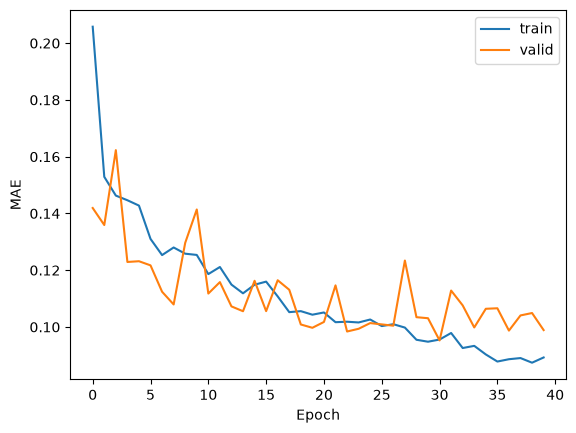

In [66]:
import matplotlib.pyplot as plt

epochs = [x["epoch"] for x in history]
train_loss = [x["train_mae"] for x in history]
valid_loss = [x["valid_mae"] for x in history]

fig, ax = plt.subplots()
ax.plot(epochs, train_loss, label="train")
ax.plot(epochs, valid_loss, label="valid")
ax.set(xlabel="Epoch", ylabel="MAE")
plt.legend()
plt.show()

In [67]:
model.load_state_dict(torch.load('elastic-model.pt'))

test_loss, test_mae = evaluate(
    model, test_loader, criterion, device
)

print(f"Test MAE: {test_mae:8.4f}")

Test MAE:   0.0958


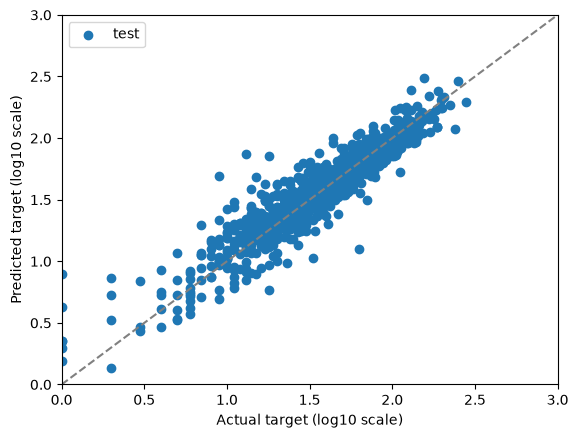

In [68]:
actual = []
predicted = []

model.eval()
with torch.no_grad():
    for i, batch in enumerate(test_loader):
        batch.to(device)
        y_pred = model(batch)
        predicted.extend(y_pred.data.cpu().tolist())
        actual.extend(batch.target.tolist())

fig, ax = plt.subplots()
ax.scatter(actual, predicted, label="test")
ax.plot([0, 3], [0, 3], ls="--", c="grey")
ax.set(
    xlabel="Actual target (log10 scale)",
    ylabel="Predicted target (log10 scale)",
    xlim=(0, 3),
    ylim=(0, 3)
)
plt.legend()
plt.show()

In [89]:
def get_loss(num_convolutions=3):
    model = CGCNN(
        NUM_NODE_FEATURES,
        NUM_EDGE_FEATURES,
        num_graph_conv_layers=num_convolutions
    )

    optimizer = torch.optim.AdamW(model.parameters())
    criterion = nn.MSELoss()

    model = model.to(device)
    criterion = criterion.to(device)

    best_valid_loss = float('inf')
    model_name = f"elastic-model-num-conv={num_convolutions}.pt"

    for epoch in range(EPOCHS):
        train_loss, train_mae = train(
            model, train_loader, criterion, optimizer, device
        )
        valid_loss, valid_mae = evaluate(
            model, valid_loader, criterion, device
        )

        if valid_loss < best_valid_loss:
            best_valid_loss = valid_loss
            torch.save(model.state_dict(), model_name)

    model.load_state_dict(torch.load(model_name))
    valid_loss, valid_mae = evaluate(
        model, valid_loader, criterion, device
    )

    return valid_mae
        

In [90]:
score = get_loss(1)
print(f"1 convolution | Validation MAE: {score:.4f}")

1 convolution | Validation MAE: 0.1026


In [80]:
convolutions = [1, 2, 3, 4]
losses = [score]

for num_convolutions in convolutions[1:]:
    print(f"Training with {num_convolutions} convolutions...")

    validation_mae = get_loss(num_convolutions)
    losses.append(validation_mae)

    print(
        f"{num_convolutions} convolutions"
        f" | Validation MAE: {validation_mae:.4f}"
    )

Training with 2 convolutions...
2 convolutions | Validation MAE: 0.1000
Training with 3 convolutions...
3 convolutions | Validation MAE: 0.0987
Training with 4 convolutions...
4 convolutions | Validation MAE: 0.0955


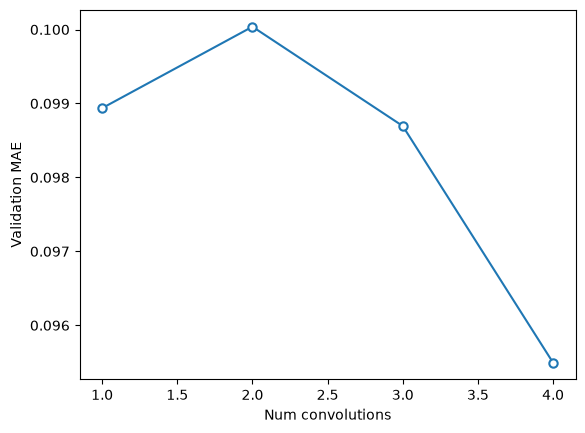

In [81]:
fig, ax = plt.subplots()

ax.plot(
    convolutions, losses,
    marker="o",
    markeredgecolor="C0",
    markerfacecolor="w",
    markeredgewidth=1.5
)

ax.set(
    xlabel="Num convolutions",
    ylabel="Validation MAE"
)

plt.show()

In [82]:
def get_loss(num_convolutions=3, node_hidden_dim=64):
    """Train and evaluate a CGCNN model."""
    
    model = CGCNN(
        NUM_NODE_FEATURES,
        NUM_EDGE_FEATURES,
        num_graph_conv_layers=num_convolutions,
        node_hidden_dim=node_hidden_dim,        
    )

    optimizer = torch.optim.AdamW(model.parameters())
    criterion = nn.MSELoss()
    
    model = model.to(device)
    criterion = criterion.to(device)
    
    best_valid_loss = float('inf')
    model_name = f"elastic-model-num-conv={num_convolutions}-node-hidden={node_hidden_dim}.pt"
    
    for epoch in range(EPOCHS):
        
        train_loss, train_mae = train(model, train_loader, criterion, optimizer, device)
        valid_loss, valid_mae = evaluate(model, valid_loader, criterion, device)
    
        if valid_loss < best_valid_loss:
            best_valid_loss = valid_loss
            torch.save(model.state_dict(), model_name)

    model.load_state_dict(torch.load(model_name))
    test_loss, test_mae = evaluate(model, test_loader, criterion, device)
    return test_mae

In [87]:
node_hidden_dims = [16, 32, 64, 128, 256]
losses = []
for node_hidden_dim in node_hidden_dims:
    print(f"Running node_hidden_dim = {node_hidden_dim}")
    loss = get_loss(node_hidden_dim=node_hidden_dim)
    losses.append(loss)

Running node_hidden_dim = 16
Running node_hidden_dim = 32
Running node_hidden_dim = 64
Running node_hidden_dim = 128
Running node_hidden_dim = 256


[Text(0.5, 0, 'Node hidden dimension'), Text(0, 0.5, 'MAE')]

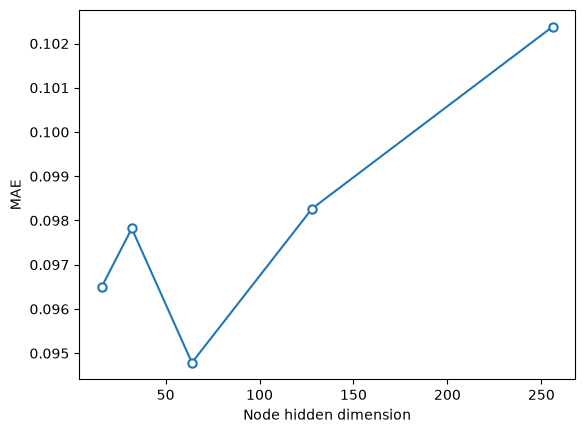

In [88]:
fig, ax = plt.subplots()
ax.plot(node_hidden_dims, losses, marker="o", markeredgecolor="C0", markerfacecolor="w", markeredgewidth=1.5)
ax.set(xlabel="Node hidden dimension", ylabel="MAE")

In [85]:
embedding_valid_maes = []

for width in node_hidden_dims:
    candidate = CGCNN(
        NUM_NODE_FEATURES,
        NUM_EDGE_FEATURES,
        num_graph_conv_layers=3,
        node_hidden_dim=width
    ).to(device)

    filename = f"elastic-model-num-conv=3-node-hidden={width}.pt"
    candidate.load_state_dict(torch.load(filename))

    valid_loss, valid_mae = evaluate(
        candidate, valid_loader, criterion, device
    )
    embedding_valid_maes.append(valid_mae)

    print(f"{width} features | Validation MAE: {valid_mae:.4f}")

16 features | Validation MAE: 0.1005
32 features | Validation MAE: 0.1003
64 features | Validation MAE: 0.0994
128 features | Validation MAE: 0.0958
256 features | Validation MAE: 0.0975


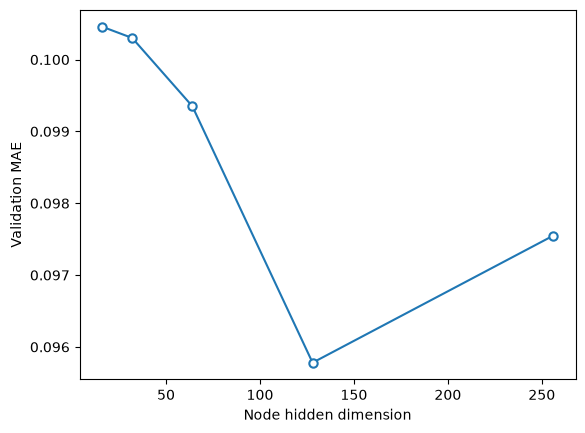

In [86]:
fig, ax = plt.subplots()

ax.plot(
    node_hidden_dims, embedding_valid_maes,
    marker="o",
    markeredgecolor="C0",
    markerfacecolor="w",
    markeredgewidth=1.5
)

ax.set(
    xlabel="Node hidden dimension",
    ylabel="Validation MAE"
)

plt.show()